# 04 · Minería no supervisada

Tres análisis, con las funciones de `src/mineria` (probadas en
`tests/test_mineria.py`):

1. **K-means sobre la forma del día**: cada día dividido por su media, para que
   la tendencia no decida los grupos. El calendario NO entra al algoritmo; se
   usa después para leer los grupos.
2. **Reglas de asociación (Apriori)** entre grupo, tipo de día, nivel y clima.
3. **Sectores CIIU por perfil semanal**: qué subactividades se comportan como
   industria de proceso continuo.

Las figuras del informe salen de `python scripts/mineria_no_supervisada.py`.

In [1]:
import sys, warnings
from pathlib import Path

# Sube desde la carpeta del notebook hasta la raiz del proyecto, la que contiene
# src/ingesta: funciona igual en notebooks/ que en notebooks/limpieza/<dataset>/.
RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "ingesta").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

DATASETS = RAIZ / "datasets"
print("raiz     :", RAIZ)
print("datasets :", DATASETS, "->", "existe" if DATASETS.exists() else "FALTA")

raiz     : C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER
datasets : C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER\datasets -> existe


In [2]:
PROCESADO = RAIZ / "data" / "procesado"
panel = pd.read_parquet(PROCESADO / "panel_modelado.parquet")
print(f"{len(panel):,} filas x {panel.shape[1]} columnas · {panel.fecha_hora.min()} .. {panel.fecha_hora.max()}")

49,824 filas x 25 columnas · 2021-01-01 00:00:00-05:00 .. 2026-09-07 23:00:00-05:00


In [3]:
from mineria.perfiles import perfiles_diarios, forma_y_nivel, atributos_dia
perfiles, registro = perfiles_diarios(panel)
forma, nivel = forma_y_nivel(perfiles)
atributos = atributos_dia(panel, perfiles.index)
registro

{'operacion': 'perfiles_diarios',
 'criterio': 'un dia entra si tiene las 24 horas con valor observado (sin NaN ni imputados); se descartan los ultimos 5 dias por publicacion parcial',
 'dias_totales': 2076,
 'dias_incompletos': 0,
 'dias_publicacion_parcial': 5,
 'dias_resultantes': 2071,
 'rango': ['2021-01-01', '2026-09-02']}

## Elección de k

Silueta como criterio, estabilidad (ARI entre semillas y submuestras) como freno.

In [4]:
from mineria.clustering import evaluar_k, elegir_k, agrupar, describir, contingencia, v_cramer, dias_atipicos
evaluacion = evaluar_k(forma.to_numpy(), ks=range(2, 11))
k = elegir_k(evaluacion)
print("k elegido:", k)
evaluacion.round(3)

k elegido: 2


,k,inercia,silueta,davies_bouldin,calinski_harabasz,tamano_minimo,estabilidad_ari
0,2,17.974,0.551,0.693,2698.950,460,0.994
1,3,12.800,0.401,0.948,2311.947,393,0.991
2,4,10.514,0.312,1.141,2025.491,312,0.965
3,5,9.376,0.277,1.238,1765.167,134,0.888
4,6,8.378,0.251,1.283,1628.974,136,0.962
5,7,7.753,0.246,1.311,1493.927,133,0.934
6,8,7.277,0.238,1.294,1382.734,130,0.904
7,9,6.889,0.222,1.369,1292.091,87,0.891
8,10,6.587,0.208,1.406,1211.072,74,0.650


In [5]:
resultado = agrupar(forma, k)
print(f"silueta {resultado.silueta:.3f} · ARI frente a Ward {resultado.ari_ward:.3f}")
describir(resultado, forma, nivel, atributos)

silueta 0.551 · ARI frente a Ward 0.846


,dias,pct_dias,nivel_medio_mwh,hora_pico,hora_valle,pico_sobre_media,valle_sobre_pico,factor_carga,pct_laboral,pct_sabado,pct_domingo,pct_festivo,pct_es_semana_santa,pct_es_ultima_semana_diciembre,pct_es_puente,temperatura_media_c,dia_mas_comun
grupo,,,,,,,,,,,,,,,,,
G1,1611,77.79,9320.7,19,3,1.136,0.722,0.880,85.7,14.1,0.0,0.2,1.2,1.1,3.0,18.69,martes
G2,460,22.21,8401.6,19,6,1.154,0.743,0.866,1.3,13.9,63.0,21.7,4.8,3.7,30.7,18.83,domingo


In [6]:
tabla = contingencia(resultado, atributos)
print("V de Cramér grupo x tipo de día:", round(v_cramer(tabla), 3))
tabla

V de Cramér grupo x tipo de día: 0.914


tipo_dia,domingo,festivo,laboral,sabado
grupo,,,,
G1,0,3,1381,227
G2,290,100,6,64


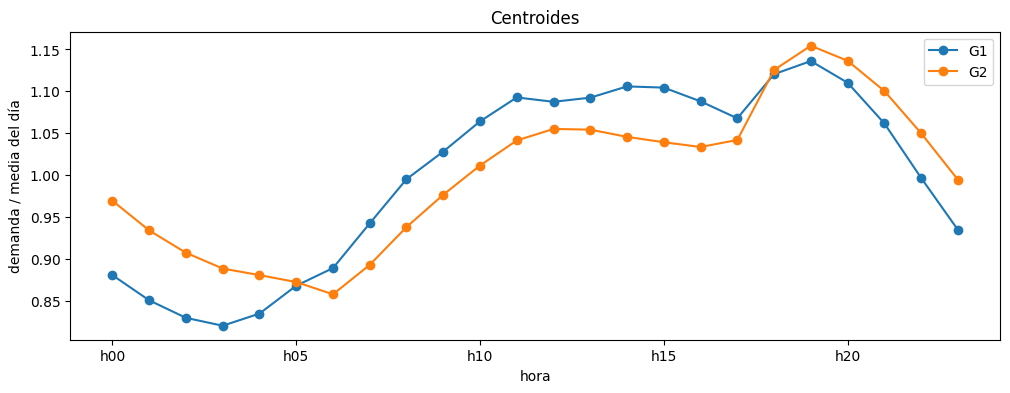

In [7]:
fig, eje = plt.subplots(figsize=(12, 4))
resultado.centroides.T.plot(ax=eje, marker="o")
eje.set_xlabel("hora"); eje.set_ylabel("demanda / media del día"); eje.set_title("Centroides");

## Días que no se parecen a su grupo

In [8]:
dias_atipicos(resultado, atributos, cuantil=0.99).head(15)

,grupo,distancia,nombre_dia,tipo_dia,nombre_festivo
fecha,,,,,
2026-01-01,G2,0.3221,jueves,festivo,Año Nuevo
2025-01-01,G2,0.2413,miercoles,festivo,Año Nuevo
2025-12-24,G2,0.2309,miercoles,laboral,None
2023-09-02,G1,0.2214,sabado,sabado,None
2025-01-06,G2,0.2172,lunes,festivo,Día de los Reyes Magos
2023-09-11,G1,0.2161,lunes,laboral,None
2023-01-01,G2,0.2112,domingo,festivo,Año Nuevo
2024-12-07,G1,0.2095,sabado,sabado,None
2022-12-24,G2,0.2081,sabado,sabado,None


## Reglas de asociación

In [9]:
from mineria.reglas import transacciones, reglas_asociacion, podar_redundantes, reglas_hacia
canasta = transacciones(atributos, resultado.etiquetas, nivel)
reglas = podar_redundantes(reglas_asociacion(canasta))
print(len(reglas), "reglas no redundantes")
reglas_hacia(reglas, "grupo=").head(10)

49

 reglas no redundantes


,antecedente,consecuente,soporte,confianza,lift,n_items
0,dia=domingo,grupo=G2,0.1400,1.0000,4.502,2
1,puente & vispera_festivo,grupo=G2,0.0304,1.0000,4.502,3
2,dia=festivo,grupo=G2,0.0483,0.9709,4.371,2
3,nivel=bajo & vispera_festivo,grupo=G2,0.0362,0.9036,4.068,3
4,nivel=bajo & puente,grupo=G2,0.0637,0.7904,3.559,3
5,nivel=bajo & temp=calida,grupo=G2,0.0662,0.7697,3.465,3
6,puente & temp=calida,grupo=G2,0.0203,0.7636,3.438,3
7,puente,grupo=G2,0.0681,0.7460,3.359,2
8,vispera_festivo,grupo=G2,0.0367,0.7451,3.355,2
9,nivel=bajo,grupo=G2,0.2067,0.6185,2.785,2


In [10]:
reglas.head(15)

,antecedente,consecuente,soporte,confianza,lift,n_items
0,dia=domingo & puente,vispera_festivo,0.0304,1.0000,20.304,3
1,dia=domingo & vispera_festivo,puente,0.0304,1.0000,10.958,3
2,grupo=G2 & vispera_festivo,puente,0.0304,0.8289,9.083,3
3,nivel=bajo & vispera_festivo,puente,0.0304,0.7590,8.317,3
4,puente & vispera_festivo,dia=domingo,0.0304,1.0000,7.141,3
5,vispera_festivo,puente,0.0304,0.6176,6.768,2
6,dia=festivo & nivel=bajo,puente,0.0304,0.6176,6.768,3
7,dia=festivo,puente,0.0304,0.6117,6.702,2
8,grupo=G1 & puente,dia=sabado,0.0217,0.9375,6.672,3
9,grupo=G2 & vispera_festivo,dia=domingo,0.0304,0.8289,5.920,3


## Sectores CIIU por perfil semanal

Requiere `datasets/limpios/ciiu_limpio.parquet` (notebook `limpieza/xm_ciiu`).

In [11]:
ruta_ciiu = DATASETS / "limpios" / "ciiu_limpio.parquet"
if ruta_ciiu.exists():
    from sklearn.cluster import KMeans
    from mineria.sectores import perfiles_sectoriales, describir_sectores, ordenar_por_tamano, mayores_por_grupo
    ciiu = pd.read_parquet(ruta_ciiu, columns=["timestamp", "activity", "subactivity", "valor", "origen_valor"])
    perf, energia, reg = perfiles_sectoriales(ciiu)
    del ciiu
    ev = evaluar_k(perf.to_numpy(), ks=range(2, 9))
    ks = elegir_k(ev, tamano_minimo=5)
    etiquetas = pd.Series(ordenar_por_tamano(KMeans(ks, n_init=20, random_state=42).fit_predict(perf.to_numpy())), index=perf.index)
    display(reg, describir_sectores(perf, energia, etiquetas), mayores_por_grupo(energia, etiquetas))
else:
    print("Falta", ruta_ciiu, "-> ejecuta notebooks/limpieza/xm_ciiu")

C:\Users\manue\OneDrive\Documentos\PROYECTOS PORTAFOLIO REAL\SIEM EXPLORER\.venv\Lib\site-packages\pyarrow\pandas_compat.py:722: DeprecationWarning: DatetimeTZBlock is deprecated and will be removed in a future version. Use public APIs instead.
  klass=_int.DatetimeTZBlock,


{'operacion': 'perfiles_sectoriales',
 'criterio': 'media de cada hora de la semana sobre valores observados, dividida por la media del sector; se exigen >= 1344 observaciones y las 168 horas de la semana con dato',
 'sectores_entrada': 367,
 'sectores_pocos_datos': 1,
 'sectores_semana_incompleta': 3,
 'sectores_media_no_positiva': 0,
 'sectores_resultantes': 363}

,sectores,pct_energia,domingo_sobre_laboral,noche_sobre_dia,factor_carga,pct_sectores_manufactura,pct_energia_manufactura
grupo,,,,,,,
S1,265,95.45,0.755,0.782,0.755,35.5,41.7
S2,98,4.55,0.451,0.344,0.553,27.6,16.2


,activity,subactivity,energia_kwh,grupo
0,EXPLOTACIÓN DE MINAS Y CANTERAS,EXTRACCIÓN DE PETRÓLEO CRUDO,2.789811e+10,S1
1,EXPLOTACIÓN DE MINAS Y CANTERAS,EXTRACCIÓN DE MINERALES DE NÍQUEL,7.322736e+09,S1
2,INDUSTRIAS MANUFACTURERAS,FABRICACIÓN DE ARTÍCULOS DE PLÁSTICO N.C.P.,5.805030e+09,S1
3,INDUSTRIAS MANUFACTURERAS,INDUSTRIAS BÁSICAS DE HIERRO Y DE ACERO,5.494580e+09,S1
4,DISTRIBUCIÓN DE AGUA; EVACUACIÓN Y TRATAMIENTO...,"CAPTACIÓN, TRATAMIENTO Y DISTRIBUCIÓN DE AGUA",4.314104e+09,S1
5,ACTIVIDADES INMOBILIARIAS,ACTIVIDADES INMOBILIARIAS REALIZADAS CON BIENE...,1.159096e+09,S2
6,EDUCACIÓN,EDUCACIÓN DE UNIVERSIDADES,1.129133e+09,S2
7,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,COMERCIO AL POR MENOR EN ESTABLECIMIENTOS NO E...,6.809491e+08,S2
8,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,COMERCIO AL POR MAYOR DE OTROS PRODUCTOS N.C.P.,3.204188e+08,S2
9,EXPLOTACIÓN DE MINAS Y CANTERAS,"EXTRACCIÓN DE PIEDRA, ARENA, ARCILLAS COMUNES,...",2.961434e+08,S2
